In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# CELL 1 : FIND PROPOSED + BASELINE CSV FILES
# ============================================================

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from IPython.display import display

print("=" * 70)
print("STATISTICAL ANALYSIS")
print("PROPOSED vs BASELINE")
print("=" * 70)

# Find all CSV files in Kaggle input
csv_files = glob.glob(
    "/kaggle/input/**/*.csv",
    recursive=True
)

print("\nCSV FILES FOUND:\n")

if len(csv_files) == 0:
    print("❌ No CSV files found.")
else:
    for i, file in enumerate(csv_files):
        print(f"{i} : {file}")

print("\nTotal CSV files found:", len(csv_files))
print("=" * 70)

STATISTICAL ANALYSIS
PROPOSED vs BASELINE

CSV FILES FOUND:

0 : /kaggle/input/datasets/srujanamannepuli/results/10_fold_results_mean_std.csv
1 : /kaggle/input/datasets/srujanamannepuli/results/baseline_10fold_mean_std.csv

Total CSV files found: 2


In [2]:
# ============================================================
# CELL 2 : LOAD + VERIFY PROPOSED AND BASELINE RESULTS
# ============================================================

import pandas as pd

# Exact paths
PROPOSED_PATH = (
    "/kaggle/input/datasets/srujanamannepuli/"
    "results/10_fold_results_mean_std.csv"
)

BASELINE_PATH = (
    "/kaggle/input/datasets/srujanamannepuli/"
    "results/baseline_10fold_mean_std.csv"
)

# Load CSV files
proposed_df = pd.read_csv(PROPOSED_PATH)
baseline_df = pd.read_csv(BASELINE_PATH)

print("=" * 80)
print("PROPOSED MODEL — DWT + EfficientNet-B4")
print("=" * 80)

display(proposed_df)

print("\nColumns:")
print(proposed_df.columns.tolist())

print("\nShape:", proposed_df.shape)


print("\n" + "=" * 80)
print("BASELINE MODEL — RGB + EfficientNet-B4")
print("=" * 80)

display(baseline_df)

print("\nColumns:")
print(baseline_df.columns.tolist())

print("\nShape:", baseline_df.shape)

print("\n" + "=" * 80)
print("✅ BOTH FILES LOADED SUCCESSFULLY")
print("=" * 80)

PROPOSED MODEL — DWT + EfficientNet-B4


,Fold,Accuracy,Loss,Precision,Recall,F1,AUC
0,1,94.600000,0.134000,0.974500,0.916000,0.94430,0.989700
1,2,92.600000,0.155800,0.934700,0.916000,0.92530,0.987100
2,3,93.400000,0.179000,0.965700,0.900000,0.93170,0.981900
3,4,90.800000,0.210600,0.939700,0.872000,0.90460,0.975000
4,5,93.200000,0.195700,0.950000,0.912000,0.93060,0.980400
5,6,93.800000,0.165300,0.966000,0.908000,0.93610,0.982800
6,7,93.990000,0.186600,0.978200,0.899600,0.93720,0.982300
7,8,94.180000,0.147000,0.954400,0.927400,0.94070,0.986700
8,9,93.000000,0.184100,0.949800,0.908000,0.92840,0.980600
9,10,95.600000,0.155400,0.956000,0.956000,0.95600,0.989200



Columns:
['Fold', 'Accuracy', 'Loss', 'Precision', 'Recall', 'F1', 'AUC']

Shape: (12, 7)

BASELINE MODEL — RGB + EfficientNet-B4


,Fold,Accuracy,Loss,Precision,Recall,F1,AUC,Best_Epoch
0,1,93.400000,0.203150,0.950207,0.916000,0.932790,0.981424,9.0
1,2,91.400000,0.287087,0.936709,0.888000,0.911704,0.966304,8.0
2,3,91.400000,0.265488,0.905882,0.924000,0.914851,0.973520,8.0
3,4,90.800000,0.226762,0.914634,0.900000,0.907258,0.976416,9.0
4,5,88.800000,0.300769,0.891129,0.884000,0.887550,0.964864,10.0
5,6,91.000000,0.234191,0.881041,0.948000,0.913295,0.976080,8.0
6,7,93.587174,0.199223,0.928854,0.943775,0.936255,0.979357,8.0
7,8,92.570281,0.254182,0.916996,0.935484,0.926148,0.974323,10.0
8,9,91.400000,0.293644,0.905882,0.924000,0.914851,0.962096,7.0
9,10,94.200000,0.199728,0.947368,0.936000,0.941650,0.981808,9.0



Columns:
['Fold', 'Accuracy', 'Loss', 'Precision', 'Recall', 'F1', 'AUC', 'Best_Epoch']

Shape: (12, 8)

✅ BOTH FILES LOADED SUCCESSFULLY


In [3]:
# ============================================================
# CELL 3 : EXTRACT 10 FOLDS + PROPOSED VS BASELINE COMPARISON
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. KEEP ONLY FOLD 1 TO FOLD 10
# Mean / Std rows automatically removed
# ------------------------------------------------------------

proposed_10 = proposed_df.iloc[:10].copy()
baseline_10 = baseline_df.iloc[:10].copy()

# ------------------------------------------------------------
# 2. CONVERT ACCURACY TO NUMERIC
# ------------------------------------------------------------

proposed_acc = pd.to_numeric(
    proposed_10["Accuracy"],
    errors="coerce"
).to_numpy()

baseline_acc = pd.to_numeric(
    baseline_10["Accuracy"],
    errors="coerce"
).to_numpy()

# Safety check
assert len(proposed_acc) == 10
assert len(baseline_acc) == 10

assert not np.isnan(proposed_acc).any(), \
    "NaN found in proposed accuracies."

assert not np.isnan(baseline_acc).any(), \
    "NaN found in baseline accuracies."

# ------------------------------------------------------------
# 3. DIFFERENCE FOR EACH FOLD
# Positive = Proposed is better
# ------------------------------------------------------------

difference = proposed_acc - baseline_acc

# ------------------------------------------------------------
# 4. CREATE COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Fold": np.arange(1, 11),

    "Proposed_Accuracy": proposed_acc,

    "Baseline_Accuracy": baseline_acc,

    "Difference": difference
})

# ------------------------------------------------------------
# 5. DISPLAY
# ------------------------------------------------------------

print("=" * 80)
print("PROPOSED vs BASELINE — FOLD-WISE ACCURACY")
print("=" * 80)

display(
    comparison_df.round(4)
)

# ------------------------------------------------------------
# 6. BASIC SUMMARY
# ------------------------------------------------------------

proposed_mean = np.mean(proposed_acc)
proposed_std = np.std(
    proposed_acc,
    ddof=1
)

baseline_mean = np.mean(baseline_acc)
baseline_std = np.std(
    baseline_acc,
    ddof=1
)

mean_difference = np.mean(
    difference
)

print("\n" + "=" * 70)
print("PRELIMINARY COMPARISON")
print("=" * 70)

print(
    f"Proposed : "
    f"{proposed_mean:.2f} ± {proposed_std:.2f}%"
)

print(
    f"Baseline : "
    f"{baseline_mean:.2f} ± {baseline_std:.2f}%"
)

print(
    f"Mean Difference "
    f"(Proposed - Baseline): "
    f"{mean_difference:.2f} percentage points"
)

print("-" * 70)

print(
    "Proposed better folds :",
    np.sum(difference > 0),
    "/ 10"
)

print(
    "Baseline better folds :",
    np.sum(difference < 0),
    "/ 10"
)

print(
    "Equal folds           :",
    np.sum(difference == 0),
    "/ 10"
)

print("=" * 70)

# ------------------------------------------------------------
# 7. SAVE COMPARISON CSV
# ------------------------------------------------------------

comparison_df.to_csv(
    "proposed_vs_baseline_fold_comparison.csv",
    index=False
)

print(
    "\n✅ Saved: proposed_vs_baseline_fold_comparison.csv"
)

PROPOSED vs BASELINE — FOLD-WISE ACCURACY


,Fold,Proposed_Accuracy,Baseline_Accuracy,Difference
0,1,94.60,93.4000,1.2000
1,2,92.60,91.4000,1.2000
2,3,93.40,91.4000,2.0000
3,4,90.80,90.8000,0.0000
4,5,93.20,88.8000,4.4000
5,6,93.80,91.0000,2.8000
6,7,93.99,93.5872,0.4028
7,8,94.18,92.5703,1.6097
8,9,93.00,91.4000,1.6000
9,10,95.60,94.2000,1.4000



PRELIMINARY COMPARISON
Proposed : 93.52 ± 1.28%
Baseline : 91.86 ± 1.61%
Mean Difference (Proposed - Baseline): 1.66 percentage points
----------------------------------------------------------------------
Proposed better folds : 9 / 10
Baseline better folds : 0 / 10
Equal folds           : 1 / 10

✅ Saved: proposed_vs_baseline_fold_comparison.csv


In [4]:
# ============================================================
# CELL 4 : STATISTICAL SIGNIFICANCE ANALYSIS
# Paired t-test + p-value + Cohen's dz + 95% CI
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

# ============================================================
# 1. PAIRED DIFFERENCES
# ============================================================

differences = proposed_acc - baseline_acc

n = len(differences)

mean_diff = np.mean(differences)

std_diff = np.std(
    differences,
    ddof=1
)

se_diff = std_diff / np.sqrt(n)


# ============================================================
# 2. PAIRED T-TEST
# H0: Mean difference = 0
# H1: Mean difference != 0
# ============================================================

t_statistic, p_value = stats.ttest_rel(
    proposed_acc,
    baseline_acc
)


# ============================================================
# 3. DEGREES OF FREEDOM
# ============================================================

df = n - 1


# ============================================================
# 4. 95% CONFIDENCE INTERVAL
# For mean paired difference
# ============================================================

confidence_level = 0.95

alpha = 1 - confidence_level

t_critical = stats.t.ppf(
    1 - alpha / 2,
    df
)

ci_lower = (
    mean_diff -
    t_critical * se_diff
)

ci_upper = (
    mean_diff +
    t_critical * se_diff
)


# ============================================================
# 5. COHEN'S dz
# Effect size for paired observations
# ============================================================

if std_diff != 0:

    cohens_dz = (
        mean_diff / std_diff
    )

else:

    cohens_dz = np.nan


# ============================================================
# 6. EFFECT SIZE INTERPRETATION
# ============================================================

abs_d = abs(cohens_dz)

if np.isnan(abs_d):

    effect_interpretation = "Undefined"

elif abs_d < 0.2:

    effect_interpretation = "Negligible"

elif abs_d < 0.5:

    effect_interpretation = "Small"

elif abs_d < 0.8:

    effect_interpretation = "Medium"

else:

    effect_interpretation = "Large"


# ============================================================
# 7. STATISTICAL SIGNIFICANCE
# ============================================================

if p_value < 0.05:

    significance = "Statistically Significant"

else:

    significance = "Not Statistically Significant"


# ============================================================
# 8. PRINT COMPLETE RESULTS
# ============================================================

print("=" * 75)
print("PAIRED STATISTICAL ANALYSIS")
print("DWT + EfficientNet-B4 vs RGB + EfficientNet-B4")
print("=" * 75)

print(
    f"Proposed Mean Accuracy : "
    f"{np.mean(proposed_acc):.2f}%"
)

print(
    f"Baseline Mean Accuracy : "
    f"{np.mean(baseline_acc):.2f}%"
)

print("-" * 75)

print(
    f"Mean Difference        : "
    f"{mean_diff:.4f} percentage points"
)

print(
    f"SD of Differences      : "
    f"{std_diff:.4f}"
)

print(
    f"Standard Error         : "
    f"{se_diff:.4f}"
)

print("-" * 75)

print(
    f"t-statistic            : "
    f"{t_statistic:.4f}"
)

print(
    f"Degrees of Freedom     : "
    f"{df}"
)

print(
    f"p-value                : "
    f"{p_value:.6f}"
)

print("-" * 75)

print(
    f"95% CI                 : "
    f"[{ci_lower:.4f}, {ci_upper:.4f}]"
)

print(
    f"Cohen's dz             : "
    f"{cohens_dz:.4f}"
)

print(
    f"Effect Size            : "
    f"{effect_interpretation}"
)

print("-" * 75)

print(
    f"Statistical Result     : "
    f"{significance}"
)

print("=" * 75)


# ============================================================
# 9. AUTOMATIC INTERPRETATION
# ============================================================

if p_value < 0.05 and mean_diff > 0:

    conclusion = (
        "The proposed DWT + EfficientNet-B4 model "
        "achieved significantly higher accuracy than "
        "the RGB + EfficientNet-B4 baseline."
    )

elif p_value < 0.05 and mean_diff < 0:

    conclusion = (
        "The baseline RGB + EfficientNet-B4 model "
        "achieved significantly higher accuracy than "
        "the proposed DWT + EfficientNet-B4 model."
    )

else:

    conclusion = (
        "The difference between the proposed and "
        "baseline models was not statistically significant."
    )

print("\nCONCLUSION:")
print(conclusion)


# ============================================================
# 10. CREATE STATISTICAL RESULTS TABLE
# ============================================================

statistical_results_df = pd.DataFrame({

    "Statistic": [
        "Proposed Mean Accuracy (%)",
        "Baseline Mean Accuracy (%)",
        "Mean Difference (percentage points)",
        "SD of Paired Differences",
        "Standard Error",
        "t-statistic",
        "Degrees of Freedom",
        "p-value",
        "95% CI Lower",
        "95% CI Upper",
        "Cohen's dz"
    ],

    "Value": [
        np.mean(proposed_acc),
        np.mean(baseline_acc),
        mean_diff,
        std_diff,
        se_diff,
        t_statistic,
        df,
        p_value,
        ci_lower,
        ci_upper,
        cohens_dz
    ]
})

display(
    statistical_results_df.round(6)
)


# ============================================================
# 11. SAVE CSV
# ============================================================

statistical_results_df.to_csv(
    "paired_ttest_statistical_results.csv",
    index=False
)

print(
    "\n✅ Saved: paired_ttest_statistical_results.csv"
)

PAIRED STATISTICAL ANALYSIS
DWT + EfficientNet-B4 vs RGB + EfficientNet-B4
Proposed Mean Accuracy : 93.52%
Baseline Mean Accuracy : 91.86%
---------------------------------------------------------------------------
Mean Difference        : 1.6613 percentage points
SD of Differences      : 1.2363
Standard Error         : 0.3910
---------------------------------------------------------------------------
t-statistic            : 4.2493
Degrees of Freedom     : 9
p-value                : 0.002145
---------------------------------------------------------------------------
95% CI                 : [0.7769, 2.5456]
Cohen's dz             : 1.3437
Effect Size            : Large
---------------------------------------------------------------------------
Statistical Result     : Statistically Significant

CONCLUSION:
The proposed DWT + EfficientNet-B4 model achieved significantly higher accuracy than the RGB + EfficientNet-B4 baseline.


,Statistic,Value
0,Proposed Mean Accuracy (%),93.517000
1,Baseline Mean Accuracy (%),91.855746
2,Mean Difference (percentage points),1.661254
3,SD of Paired Differences,1.236294
4,Standard Error,0.390950
5,t-statistic,4.249272
6,Degrees of Freedom,9.000000
7,p-value,0.002145
8,95% CI Lower,0.776863
9,95% CI Upper,2.545646



✅ Saved: paired_ttest_statistical_results.csv


FINAL STATISTICAL SUMMARY


,Measure,Result
0,Proposed Mean Accuracy (%),93.5170
1,Proposed Standard Deviation,1.2849
2,Baseline Mean Accuracy (%),91.8557
3,Baseline Standard Deviation,1.6054
4,Mean Difference (percentage points),1.6613
5,t-statistic,4.2493
6,Degrees of Freedom,9
7,p-value,0.002145
8,95% CI Lower,0.7769
9,95% CI Upper,2.5456


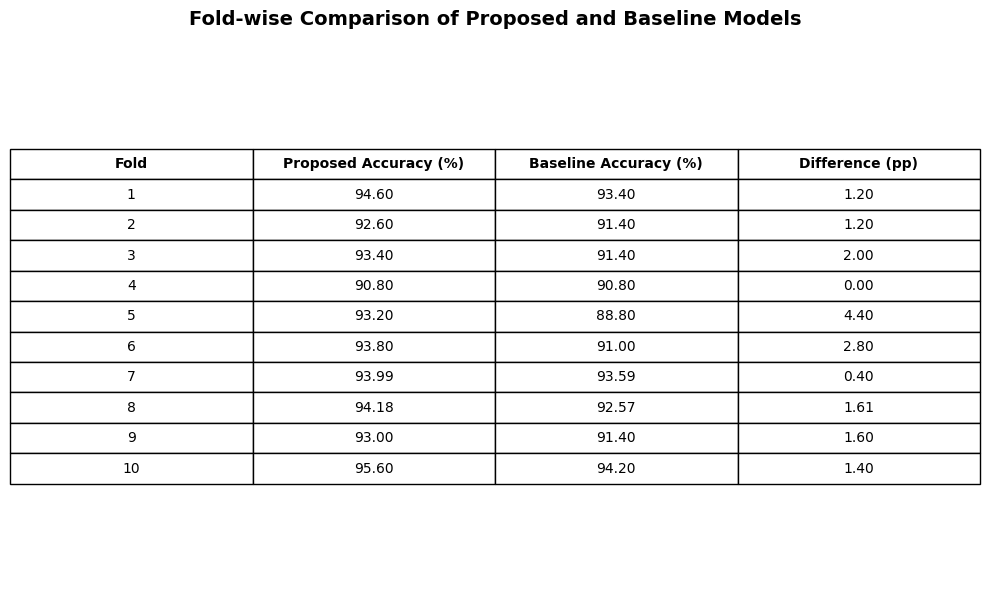

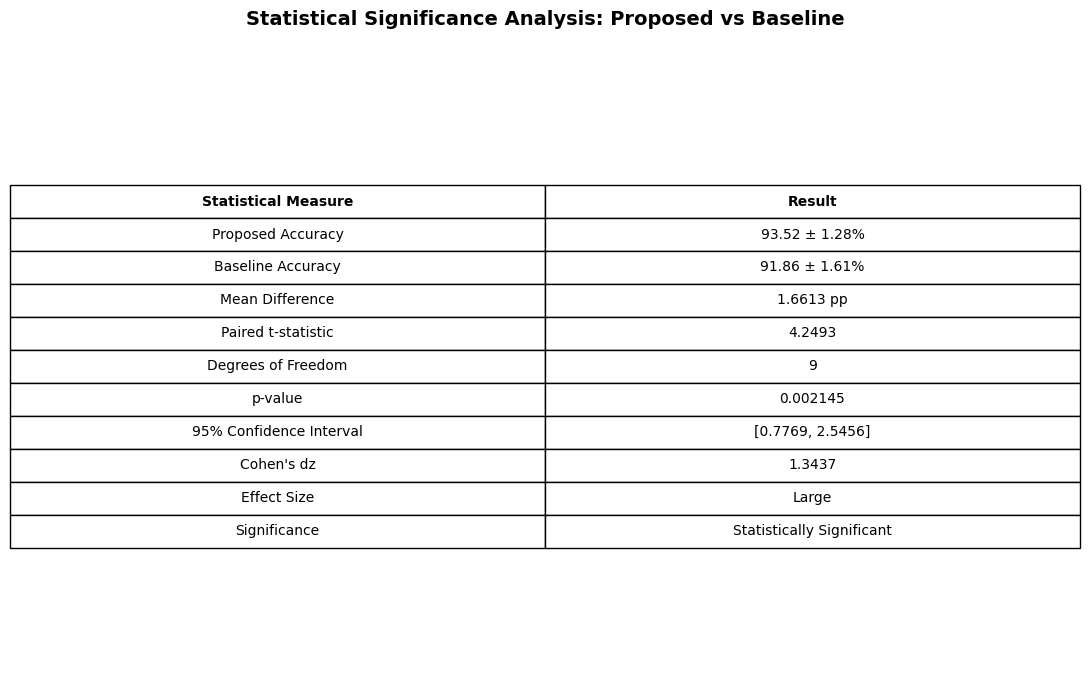

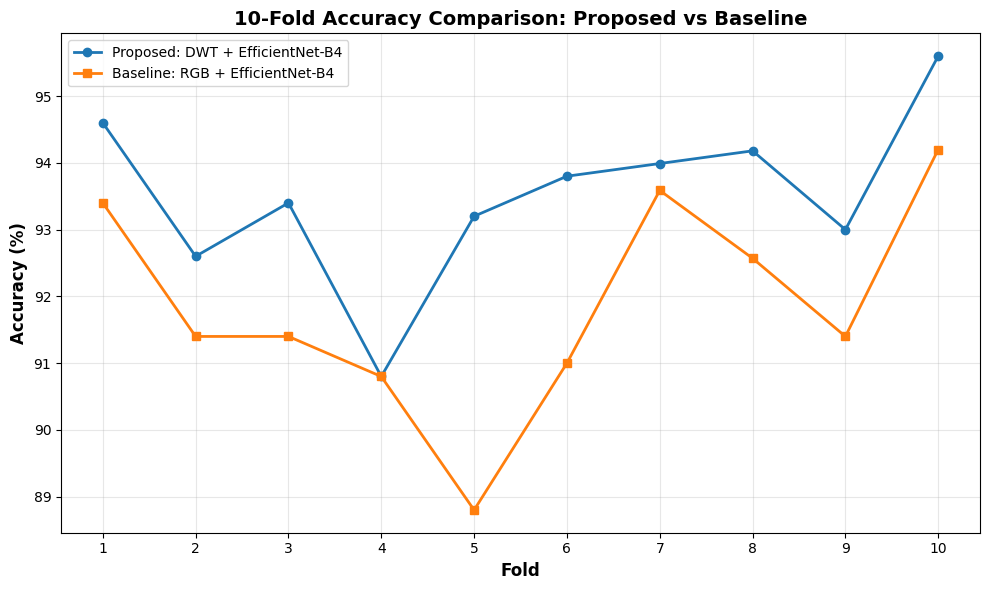

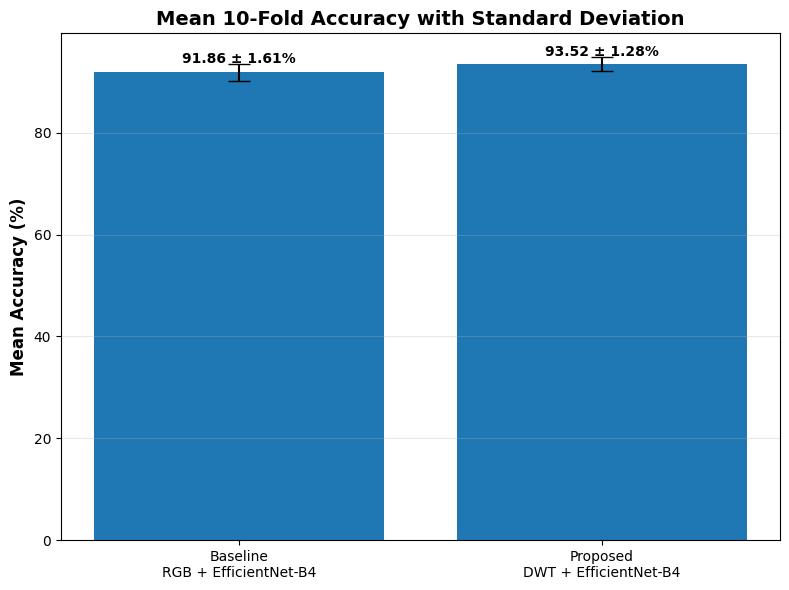

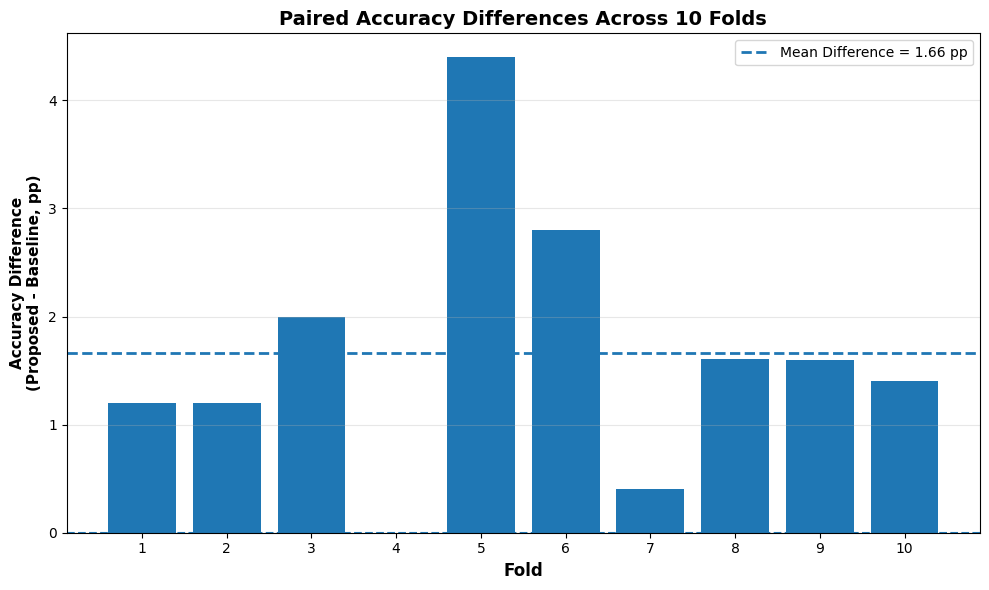


PAPER-READY RESULT
The proposed DWT + EfficientNet-B4 model achieved a mean accuracy of 93.52 ± 1.28%, compared with 91.86 ± 1.61% for the RGB + EfficientNet-B4 baseline. The mean paired difference was 1.66 percentage points (95% CI: 0.78 to 2.55). A paired-samples t-test yielded t(9) = 4.249, p = 0.002145. Cohen's dz was 1.344, indicating a large effect. The difference was statistically significant.

DOWNLOAD ALL FILES

✓ proposed_vs_baseline_fold_comparison.csv


/kaggle/working/proposed_vs_baseline_fold_comparison.csv


✓ paired_ttest_statistical_results.csv


/kaggle/working/paired_ttest_statistical_results.csv


✓ final_statistical_summary.csv


...


✓ paired_fold_accuracy_difference.png


/kaggle/working/paired_fold_accuracy_difference.png


✓ paper_statistical_result.txt


/kaggle/working/paper_statistical_result.txt


✅ ALL STATISTICAL FILES SAVED SUCCESSFULLY


In [6]:
# ============================================================
# CELL 5 : FINAL SAVE
# CSV + PNG (300 DPI) + TXT + DOWNLOAD LINKS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink


# ============================================================
# 1. PREPARE VALUES
# ============================================================

proposed_mean = np.mean(proposed_acc)
proposed_std = np.std(proposed_acc, ddof=1)

baseline_mean = np.mean(baseline_acc)
baseline_std = np.std(baseline_acc, ddof=1)

differences = proposed_acc - baseline_acc
mean_difference = np.mean(differences)


# ============================================================
# 2. SAVE FOLD COMPARISON CSV
# ============================================================

comparison_df.to_csv(
    "proposed_vs_baseline_fold_comparison.csv",
    index=False
)


# ============================================================
# 3. SAVE T-TEST RESULTS CSV
# ============================================================

statistical_results_df.to_csv(
    "paired_ttest_statistical_results.csv",
    index=False
)


# ============================================================
# 4. CREATE FINAL SUMMARY TABLE
# ============================================================

summary_data = {
    "Measure": [
        "Proposed Mean Accuracy (%)",
        "Proposed Standard Deviation",
        "Baseline Mean Accuracy (%)",
        "Baseline Standard Deviation",
        "Mean Difference (percentage points)",
        "t-statistic",
        "Degrees of Freedom",
        "p-value",
        "95% CI Lower",
        "95% CI Upper",
        "Cohen's dz",
        "Effect Size",
        "Statistical Significance"
    ],

    "Result": [
        f"{proposed_mean:.4f}",
        f"{proposed_std:.4f}",
        f"{baseline_mean:.4f}",
        f"{baseline_std:.4f}",
        f"{mean_diff:.4f}",
        f"{t_statistic:.4f}",
        f"{df}",
        f"{p_value:.6f}",
        f"{ci_lower:.4f}",
        f"{ci_upper:.4f}",
        f"{cohens_dz:.4f}",
        effect_interpretation,
        significance
    ]
}

summary_df = pd.DataFrame(summary_data)

summary_df.to_csv(
    "final_statistical_summary.csv",
    index=False
)

print("=" * 70)
print("FINAL STATISTICAL SUMMARY")
print("=" * 70)

display(summary_df)


# ============================================================
# 5. FOLD-WISE COMPARISON TABLE PNG
# ============================================================

table_df = comparison_df.copy()

table_df["Proposed_Accuracy"] = table_df[
    "Proposed_Accuracy"
].map(lambda x: f"{x:.2f}")

table_df["Baseline_Accuracy"] = table_df[
    "Baseline_Accuracy"
].map(lambda x: f"{x:.2f}")

table_df["Difference"] = table_df[
    "Difference"
].map(lambda x: f"{x:.2f}")


fig, ax = plt.subplots(figsize=(10, 6))

ax.axis("off")

table = ax.table(
    cellText=table_df.values,
    colLabels=[
        "Fold",
        "Proposed Accuracy (%)",
        "Baseline Accuracy (%)",
        "Difference (pp)"
    ],
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")

plt.title(
    "Fold-wise Comparison of Proposed and Baseline Models",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "proposed_vs_baseline_fold_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. STATISTICAL ANALYSIS TABLE PNG
# ============================================================

stat_table_data = {
    "Statistical Measure": [
        "Proposed Accuracy",
        "Baseline Accuracy",
        "Mean Difference",
        "Paired t-statistic",
        "Degrees of Freedom",
        "p-value",
        "95% Confidence Interval",
        "Cohen's dz",
        "Effect Size",
        "Significance"
    ],

    "Result": [
        f"{proposed_mean:.2f} ± {proposed_std:.2f}%",
        f"{baseline_mean:.2f} ± {baseline_std:.2f}%",
        f"{mean_diff:.4f} pp",
        f"{t_statistic:.4f}",
        str(df),
        f"{p_value:.6f}",
        f"[{ci_lower:.4f}, {ci_upper:.4f}]",
        f"{cohens_dz:.4f}",
        effect_interpretation,
        significance
    ]
}

stat_table_df = pd.DataFrame(stat_table_data)


fig, ax = plt.subplots(figsize=(11, 7))

ax.axis("off")

table = ax.table(
    cellText=stat_table_df.values,
    colLabels=stat_table_df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.7)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")

plt.title(
    "Statistical Significance Analysis: Proposed vs Baseline",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "statistical_analysis_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. FOLD-WISE ACCURACY COMPARISON GRAPH
# ============================================================

fold_numbers = np.arange(1, 11)

plt.figure(figsize=(10, 6))

plt.plot(
    fold_numbers,
    proposed_acc,
    marker="o",
    linewidth=2,
    label="Proposed: DWT + EfficientNet-B4"
)

plt.plot(
    fold_numbers,
    baseline_acc,
    marker="s",
    linewidth=2,
    label="Baseline: RGB + EfficientNet-B4"
)

plt.xticks(fold_numbers)

plt.xlabel(
    "Fold",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "10-Fold Accuracy Comparison: Proposed vs Baseline",
    fontsize=14,
    fontweight="bold"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "proposed_vs_baseline_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. MEAN ACCURACY ± SD GRAPH
# ============================================================

model_names = [
    "Baseline\nRGB + EfficientNet-B4",
    "Proposed\nDWT + EfficientNet-B4"
]

mean_values = [
    baseline_mean,
    proposed_mean
]

std_values = [
    baseline_std,
    proposed_std
]


fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(
    model_names,
    mean_values,
    yerr=std_values,
    capsize=8
)

for bar, mean_value, std_value in zip(
    bars,
    mean_values,
    std_values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        mean_value + std_value + 0.3,
        f"{mean_value:.2f} ± {std_value:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax.set_ylabel(
    "Mean Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Mean 10-Fold Accuracy with Standard Deviation",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "mean_accuracy_with_std.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. PAIRED DIFFERENCE GRAPH
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    fold_numbers,
    differences
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.axhline(
    mean_diff,
    linestyle="--",
    linewidth=2,
    label=f"Mean Difference = {mean_diff:.2f} pp"
)

ax.set_xticks(fold_numbers)

ax.set_xlabel(
    "Fold",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Accuracy Difference\n(Proposed - Baseline, pp)",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Paired Accuracy Differences Across 10 Folds",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "paired_fold_accuracy_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. PAPER-READY RESULT TEXT
# ============================================================

paper_result = (
    f"The proposed DWT + EfficientNet-B4 model achieved "
    f"a mean accuracy of {proposed_mean:.2f} ± "
    f"{proposed_std:.2f}%, compared with "
    f"{baseline_mean:.2f} ± {baseline_std:.2f}% "
    f"for the RGB + EfficientNet-B4 baseline. "
    f"The mean paired difference was "
    f"{mean_diff:.2f} percentage points "
    f"(95% CI: {ci_lower:.2f} to {ci_upper:.2f}). "
    f"A paired-samples t-test yielded "
    f"t({df}) = {t_statistic:.3f}, "
    f"p = {p_value:.6f}. "
    f"Cohen's dz was {cohens_dz:.3f}, "
    f"indicating a {effect_interpretation.lower()} effect. "
    f"The difference was {significance.lower()}."
)

with open(
    "paper_statistical_result.txt",
    "w"
) as file:
    file.write(paper_result)


print("\n" + "=" * 80)
print("PAPER-READY RESULT")
print("=" * 80)

print(paper_result)

print("=" * 80)


# ============================================================
# 11. ALL FILES TO DOWNLOAD
# ============================================================

final_files = [
    "proposed_vs_baseline_fold_comparison.csv",
    "paired_ttest_statistical_results.csv",
    "final_statistical_summary.csv",
    "proposed_vs_baseline_fold_table.png",
    "statistical_analysis_table.png",
    "proposed_vs_baseline_accuracy_comparison.png",
    "mean_accuracy_with_std.png",
    "paired_fold_accuracy_difference.png",
    "paper_statistical_result.txt"
]


# ============================================================
# 12. DOWNLOAD LINKS
# ============================================================

print("\n" + "=" * 80)
print("DOWNLOAD ALL FILES")
print("=" * 80)

for file_name in final_files:

    if os.path.exists(file_name):

        print("\n✓", file_name)

        display(
            FileLink(file_name)
        )

    else:

        print(
            "\n❌ FILE NOT FOUND:",
            file_name
        )

print("\n" + "=" * 80)
print("✅ ALL STATISTICAL FILES SAVED SUCCESSFULLY")
print("=" * 80)